<a href="https://colab.research.google.com/github/punypeony/SANTIAGO_CCADMACL_EXERCISES/blob/main/Exercise_1_CCADMACL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression



In [2]:
datasetpath = kagglehub.dataset_download("parulpandey/palmer-archipelago-antarctica-penguin-data")
dataseturl = glob.glob(os.path.join(datasetpath, "**", "penguins_size.csv"), recursive=True)[0]

Using Colab cache for faster access to the 'palmer-archipelago-antarctica-penguin-data' dataset.


In [3]:
df = pd.read_csv(dataseturl)
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [4]:
penguins = df[df["species"].isin(["Adelie", "Chinstrap"]) & df["sex"].isin(["MALE", "FEMALE"])].dropna()

data = pd.DataFrame({
    "BillLength":    penguins["culmen_length_mm"],
    "BillDepth":     penguins["culmen_depth_mm"],
    "FlipperLength": penguins["flipper_length_mm"],
    "BodyMass":      penguins["body_mass_g"] / 1000,                    # grams -> kg
    "Sex":           (penguins["sex"] == "MALE").astype(int),          # female = 0, male = 1
    "Species":       (penguins["species"] == "Chinstrap").astype(int), # 0 = Adelie, 1 = Chinstrap
})

features = ["BillLength", "BillDepth", "FlipperLength", "BodyMass", "Sex"]

train, test = train_test_split(data, test_size=0.2, stratify=data["Species"], random_state=42)

X_train, y_train = train[features], train["Species"]
X_test,  y_test  = test[features],  test["Species"]

# ---- For the visualizations ----
# Grid of (BillLength, BillDepth) points that covers the whole plot
xx, yy = np.meshgrid(np.linspace(30, 60, 300), np.linspace(14, 23, 300))
grid = pd.DataFrame({"BillLength": xx.ravel(), "BillDepth": yy.ravel()})

colors = {0: "#1f8bb5", 1: "#d1495b"}
labels = {0: "Adelie", 1: "Chinstrap"}

print("Train:", X_train.shape, " Test:", X_test.shape)
X_train.head()

Train: (171, 5)  Test: (43, 5)


,BillLength,BillDepth,FlipperLength,BodyMass,Sex
179,49.5,19.0,200.0,3.800,1
134,38.1,17.6,187.0,3.425,0
41,40.8,18.4,195.0,3.900,1
29,40.5,18.9,180.0,3.950,1
44,37.0,16.9,185.0,3.000,0


In [5]:
nb = GaussianNB()
nb.fit(X_train, y_train)

GaussianNB()

In [6]:
pred_nb = nb.predict(X_test)
acc_nb = accuracy_score(y_test, pred_nb)
print("Naive Bayes Accuracy:", acc_nb)

Naive Bayes Accuracy: 0.9534883720930233


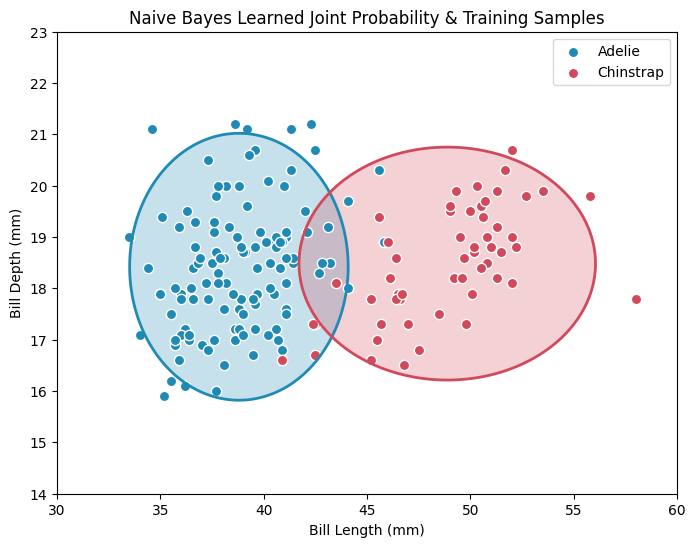

In [7]:
nb_2d = GaussianNB()
nb_2d.fit(X_train[["BillLength", "BillDepth"]], y_train)

joint_nb = np.exp(nb_2d.predict_joint_log_proba(grid))

fig, ax = plt.subplots(figsize=(8, 6))

for k in [0, 1]:
    z = joint_nb[:, k].reshape(xx.shape)
    ax.contourf(xx, yy, z, levels=[z.max() * 0.1, z.max()], colors=colors[k], alpha=0.25)
    ax.contour(xx, yy, z, levels=[z.max() * 0.1], colors=colors[k], linewidths=2)

for k in [0, 1]:
    mask = y_train == k
    ax.scatter(
        X_train.loc[mask, "BillLength"],
        X_train.loc[mask, "BillDepth"],
        c=colors[k],
        edgecolors="white",
        s=55,
        label=labels[k]
    )

ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.set_title("Naive Bayes Learned Joint Probability & Training Samples")
ax.legend()
plt.show()

In [8]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [9]:
logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [10]:
pred_lr = logreg.predict(X_test)
acc_lr = accuracy_score(y_test, pred_lr)
print("Logistic Regression Accuracy:", acc_lr)

Logistic Regression Accuracy: 1.0


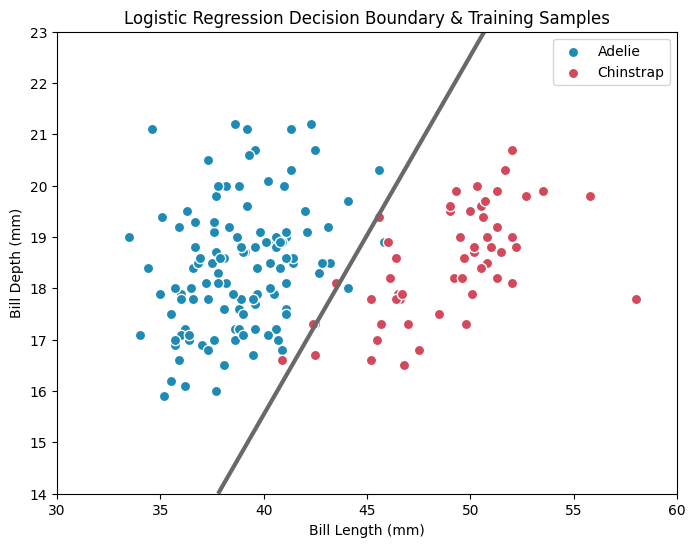

In [11]:
logreg_2d = LogisticRegression(max_iter=1000)
logreg_2d.fit(X_train[["BillLength", "BillDepth"]], y_train)

cond_lr = logreg_2d.predict_proba(grid)[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))

# Plot decision boundary (where probability of being Chinstrap is 0.5)
ax.contour(
    xx,
    yy,
    cond_lr.reshape(xx.shape),
    levels=[0.5],
    colors="dimgray",
    linewidths=3
)

# Plot training penguins as scatter dots
for k in [0, 1]:
    mask = y_train == k
    ax.scatter(
        X_train.loc[mask, "BillLength"],
        X_train.loc[mask, "BillDepth"],
        c=colors[k],
        edgecolors="white",
        s=55,
        label=labels[k]
    )

ax.set_xlabel("Bill Length (mm)")
ax.set_ylabel("Bill Depth (mm)")
ax.set_title("Logistic Regression Decision Boundary & Training Samples")
ax.legend()
plt.show()

,Model,Type,Learns,Test Accuracy
0,Naive Bayes (GaussianNB),Generative,Joint probability,0.9535
1,Logistic Regression,Discriminative,Conditional probability,1.0000


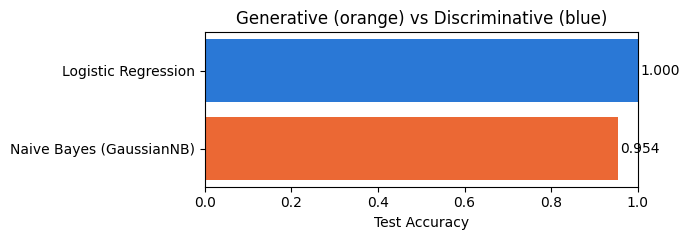

In [12]:
# Compares the generative model (Part 1) and the discriminative model (Part 2)
comparison = pd.DataFrame({
    "Model": ["Naive Bayes (GaussianNB)", "Logistic Regression"],
    "Type":  ["Generative", "Discriminative"],
    "Learns": ["Joint probability", "Conditional probability"],
    "Test Accuracy": [acc_nb, acc_lr],
}).round(4)
display(comparison)

bar_colors = comparison["Type"].map({"Generative": "#eb6834", "Discriminative": "#2a78d6"})
plt.figure(figsize=(7, 2.5))
plt.barh(comparison["Model"], comparison["Test Accuracy"], color=bar_colors)
for i, v in enumerate(comparison["Test Accuracy"]):
    plt.text(v + 0.005, i, f"{v:.3f}", va="center")
plt.xlim(0, 1)
plt.xlabel("Test Accuracy")
plt.title("Generative (orange) vs Discriminative (blue)")
plt.tight_layout()
plt.show()